In [ ]:
## Practica 1: Algoritmo de Expansión Mínima.

In [1]:
#Importar librerías
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
#Definir grafo e identificar nodos y arcos
G = nx.Graph()
#Arcos (origen, destino, peso = metros de fibra óptica)
arcos = [
    ("A","B",12), ("A","C",25), ("B","C",8), ("B","D",20),
    ("C","E",15), ("D","F",18), ("E","F",10), ("E","G",22),
    ("F","H",14), ("G","H",9)
]
G.add_weighted_edges_from(arcos)

nodos = list(G.nodes())
print(f"Nodos (Edificios): {nodos}")
print(f"Cantidad de nodos: {len(nodos)}")
print("\nArcos y sus pesos:")
for u,v,p in G.edges(data="weight"):
    print(f"{u} ↔ {v} : {p} m")

Nodos (Edificios): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
Cantidad de nodos: 8

Arcos y sus pesos:
A ↔ B : 12 m
A ↔ C : 25 m
B ↔ C : 8 m
B ↔ D : 20 m
C ↔ E : 15 m
D ↔ F : 18 m
E ↔ F : 10 m
E ↔ G : 22 m
F ↔ H : 14 m
G ↔ H : 9 m


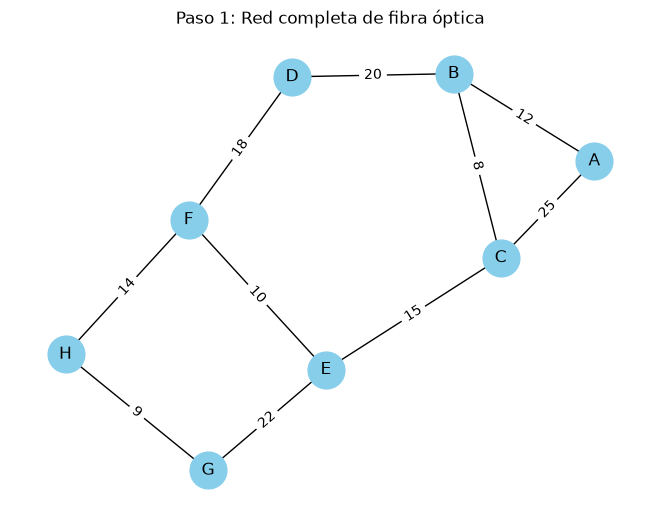

In [ ]:

#Gráfica del grafo completo 
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color="#87ceeb", node_size=700)
etiquetas = nx.get_edge_attributes(G,"weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=etiquetas)
plt.title("Grafo completo de fibra óptica")
plt.show()


In [5]:
#Ordenar arcos de menor a mayor (Paso de Kruskal)
arcos_ordenados = sorted(G.edges(data="weight"), key=lambda x: x[2])
print("Arcos ordenados:")
for u,v,p in arcos_ordenados:
    print(f"{u}-{v} = {p} m")

Arcos ordenados:
B-C = 8 m
G-H = 9 m
E-F = 10 m
A-B = 12 m
F-H = 14 m
C-E = 15 m
D-F = 18 m
B-D = 20 m
E-G = 22 m
A-C = 25 m


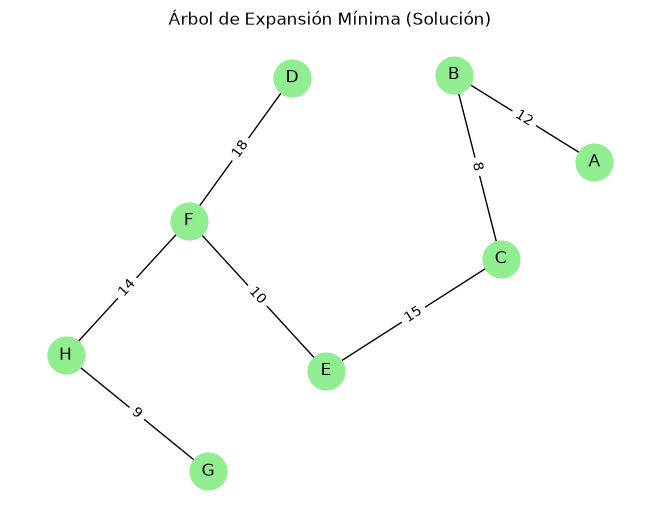

In [6]:
#Calcular y graficar el Árbol de Expansión Mínima 
aem = nx.minimum_spanning_tree(G, algorithm="kruskal")
nx.draw(aem, pos, with_labels=True, node_color="#90ee90", node_size=700)
etiquetas_aem = nx.get_edge_attributes(aem,"weight")
nx.draw_networkx_edge_labels(aem, pos, edge_labels=etiquetas_aem)
plt.title("Árbol de Expansión Mínima (Solución)")
plt.show()

In [7]:
#Cálculo del costo final
costo_total = sum(etiquetas_aem.values())
print(f"\nLongitud total de cable: {costo_total} metros")


Longitud total de cable: 86 metros
